# Notebook 2 - Detecção Estatística de Drift de Dados

## Objetivos
- Validar estatisticamente o Drift no dado sintético de produção;
- Implementar e aplicar o **teste Kolmogorov-Smirnov (KS)** para features contínuas.
- Calcular o **PSI (Population Stability Index)** com binning e log-ratio.

In [ ]:
# Imports
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Adiciona diretório raiz da aula ao path
sys.path.insert(0, str(Path.cwd().parent))

from src.utils.config_loader import PROJECT_ROOT, load_config
from src.drift.detect import DriftDetector
from src.drift.evaluation import ( 
    plot_cdf_comparison,
    plot_psi_bars,
)

sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Carga dos Dados
Carregamos os datasets 

In [3]:
num_var = [
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "AMT_ANNUITY",
    "AMT_CREDIT",
    "AMT_GOODS_PRICE",
    "AGE_YEARS",
    "CREDIT_TERM",
    "CREDIT_GOODS_PERCENT",
    "EXT_SOURCES_MEAN",
]

target_var = "TARGET"

In [8]:
# Carga dos Dados
config = load_config()
data_dir = PROJECT_ROOT / config.data.processed_path

ref_data = pd.read_csv(data_dir / config.data.reference_file)
prod1_estavel = pd.read_csv(data_dir / "prod_periodo1_estavel.csv")
prod2_drift = pd.read_csv(data_dir / "prod_periodo2_drift.csv")

## 2. Teste de Kolmogorov-Smirnov (KS)

Se o **p-valor < 0.05**, rejeitamos a hipótese nula (distribuições idênticas) -> **drift detectado**.

### 2.1 Implementação Manual

In [9]:
feature = "AGE_YEARS"

dados_ref = pd.to_numeric(ref_data[feature], errors="coerce").dropna()

for nome, dados_prod in [
    ("Prod1 estável", prod1_estavel),
    ("Prod2 driftado", prod2_drift),
]:
    dados_novos = pd.to_numeric(dados_prod[feature], errors="coerce").dropna()

    estatistica, p_valor = stats.ks_2samp(
        dados_ref.to_numpy(),
        dados_novos.to_numpy(),
    )

    print(f"\nComparação: Referência × {nome}")
    print(f"Estatística KS: {estatistica:.4f}")
    print(f"p-valor: {p_valor:.3e}")
    print(f"Drift detectado? {'SIM ✓' if p_valor < 0.05 else 'NÃO ✗'}")
    print(f"(p-valor {'<' if p_valor < 0.05 else '≥'} 0.05)")


Comparação: Referência × Prod1 estável
Estatística KS: 0.0051
p-valor: 4.669e-01
Drift detectado? NÃO ✗
(p-valor ≥ 0.05)

Comparação: Referência × Prod2 driftado
Estatística KS: 0.3948
p-valor: 0.000e+00
Drift detectado? SIM ✓
(p-valor < 0.05)


### 2.2 Visualização das CDFs (Teste KS Visual)

Prod1 estável: KS D = 0.0051, p-valor = 4.669e-01


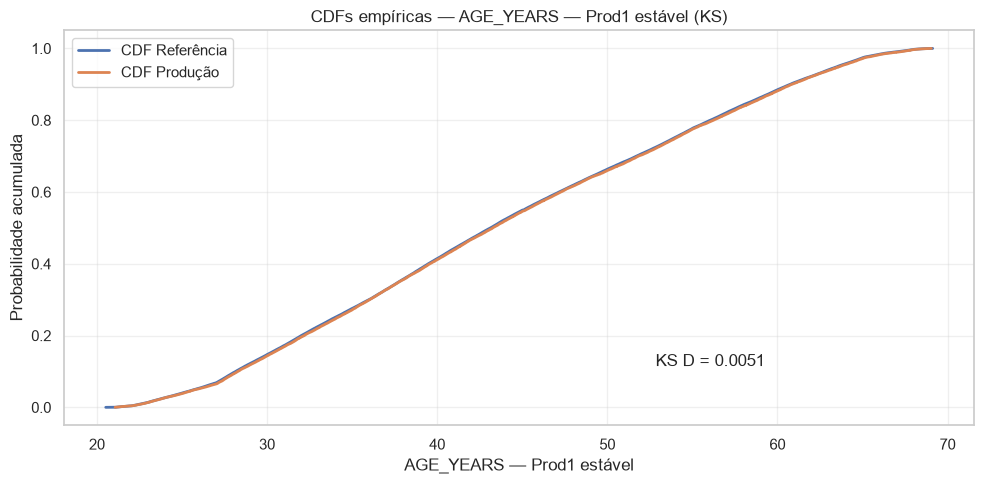

Prod2 driftado: KS D = 0.3948, p-valor = 0.000e+00


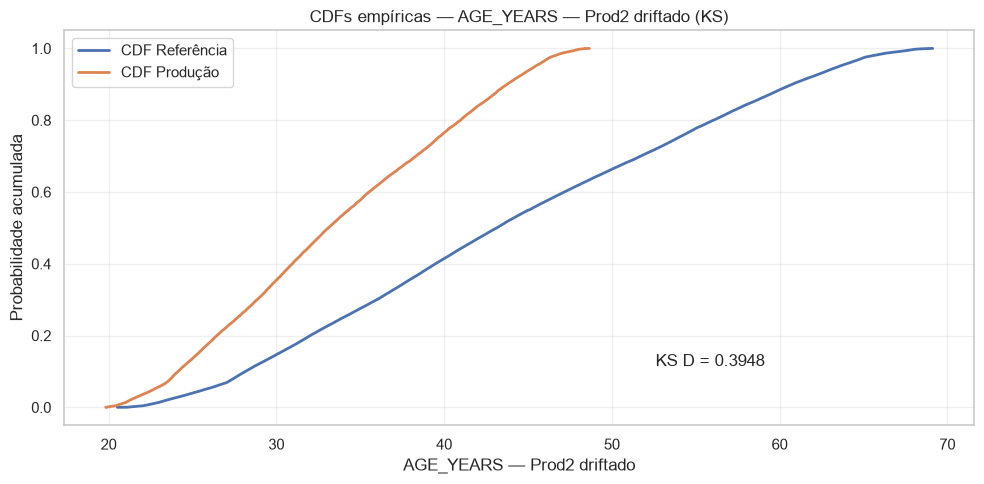

In [10]:
dados_ref = (
    pd.to_numeric(ref_data[feature], errors="coerce")
    .dropna()
    .to_numpy()
)

comparacoes = [
    ("Prod1 estável", prod1_estavel),
    ("Prod2 driftado", prod2_drift),
]

for nome, dados_prod in comparacoes:
    dados_novos = (
        pd.to_numeric(dados_prod[feature], errors="coerce")
        .dropna()
        .to_numpy()
    )

    estatistica, p_valor = stats.ks_2samp(dados_ref, dados_novos)

    print(f"{nome}: KS D = {estatistica:.4f}, p-valor = {p_valor:.3e}")

    fig = plot_cdf_comparison(
        dados_ref,
        dados_novos,
        feature_name=f"{feature} — {nome}",
        ks_statistic=estatistica,
    )
    plt.show()

### 2.3 KS Test em Todas as Features Numéricas

In [11]:
detector = DriftDetector(alpha=0.05)

features_numericas = [col for col in num_var if col != target_var]

for nome, dados_prod in [
    ("Prod1 estável", prod1_estavel),
    ("Prod2 driftado", prod2_drift),
]:
    print(f"\nReferência × {nome}")
    print(f"{'Feature':<30} {'Estatística KS':>15} {'p-valor':>15} {'Drift?':>10}")
    print("-" * 75)

    for col in features_numericas:
        result = detector.ks_test(
            ref_data[col].values,
            dados_prod[col].values,
            feature_name=col,
        )
        symbol = "✓ SIM" if result.drift_detected else "✗ NÃO"

        print(
            f"{result.feature_name:<30} "
            f"{result.statistic:>15.4f} "
            f"{result.p_value:>15.3e} "
            f"{symbol:>10}"
        )


Referência × Prod1 estável
Feature                         Estatística KS         p-valor     Drift?
---------------------------------------------------------------------------
EXT_SOURCE_1                            0.0082       4.068e-01      ✗ NÃO
EXT_SOURCE_2                            0.0028       9.812e-01      ✗ NÃO
EXT_SOURCE_3                            0.0065       3.015e-01      ✗ NÃO
AMT_ANNUITY                             0.0038       8.267e-01      ✗ NÃO
AMT_CREDIT                              0.0058       3.129e-01      ✗ NÃO
AMT_GOODS_PRICE                         0.0046       6.056e-01      ✗ NÃO
AGE_YEARS                               0.0051       4.669e-01      ✗ NÃO
CREDIT_TERM                             0.0055       3.863e-01      ✗ NÃO
CREDIT_GOODS_PERCENT                    0.0032       9.391e-01      ✗ NÃO
EXT_SOURCES_MEAN                        0.0036       8.712e-01      ✗ NÃO

Referência × Prod2 driftado
Feature                         Estatística KS       

## 3. Population Stability Index (PSI)

**Benchmarks**
- PSI < 0.10 → estável
- 0.10 ≤ PSI < 0.25 → drift moderado
- PSI ≥ 0.25 → drift severo

###

### 3.1 PSI com Binning em Features Contínuas

In [12]:
for nome, dados_prod in [
    ("Prod1 estável", prod1_estavel),
    ("Prod2 driftado", prod2_drift),
]:
    print(f"\nReferência × {nome}")
    print(f"{'Feature':<30} {'PSI':>10} {'Interpretação':>30} {'Drift?':>10}")
    print("-" * 85)

    for col in features_numericas:
        result = detector.psi(
            ref_data[col].values,
            dados_prod[col].values,
            feature_name=col,
        )
        interpretacao = DriftDetector.interpret_psi(result.statistic)
        symbol = "✓ SIM" if result.drift_detected else "✗ NÃO"

        print(
            f"{result.feature_name:<30} "
            f"{result.statistic:>10.4f} "
            f"{interpretacao:>30} "
            f"{symbol:>10}"
        )


Referência × Prod1 estável
Feature                               PSI                  Interpretação     Drift?
-------------------------------------------------------------------------------------
EXT_SOURCE_1                       0.0004           estável (PSI < 0.10)      ✗ NÃO
EXT_SOURCE_2                       0.0002           estável (PSI < 0.10)      ✗ NÃO
EXT_SOURCE_3                       0.0008           estável (PSI < 0.10)      ✗ NÃO
AMT_ANNUITY                        0.0011           estável (PSI < 0.10)      ✗ NÃO
AMT_CREDIT                         0.0003           estável (PSI < 0.10)      ✗ NÃO
AMT_GOODS_PRICE                    0.0002           estável (PSI < 0.10)      ✗ NÃO
AGE_YEARS                          0.0003           estável (PSI < 0.10)      ✗ NÃO
CREDIT_TERM                        0.0011           estável (PSI < 0.10)      ✗ NÃO
CREDIT_GOODS_PERCENT               0.0003           estável (PSI < 0.10)      ✗ NÃO
EXT_SOURCES_MEAN                   0.0004     

### 3.2 Visualização - Barras de PSI com Limiares

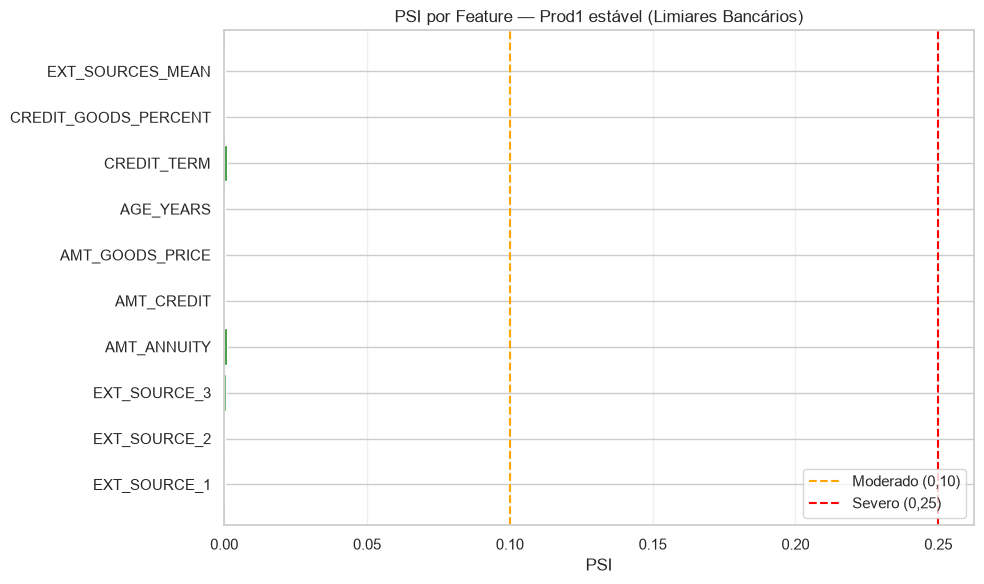

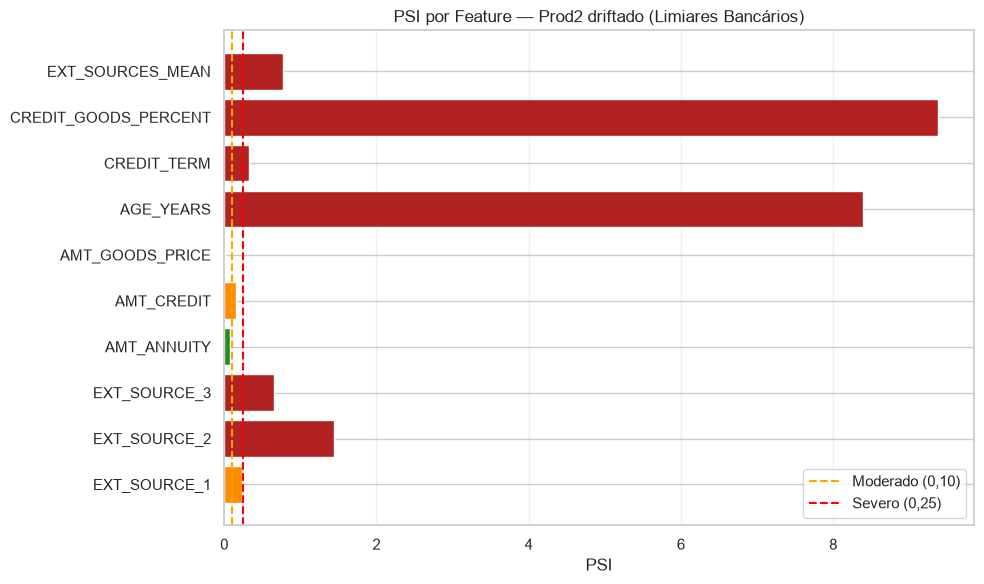

In [13]:
for nome, dados_prod in [
    ("Prod1 estável", prod1_estavel),
    ("Prod2 driftado", prod2_drift),
]:
    report_psi = detector.detect_all(
        reference_df=ref_data,
        current_df=dados_prod,
        numerical_cols=features_numericas,
        categorical_cols=[],
        methods=["psi"],
        exclude_columns=[target_var],
    )

    fig = plot_psi_bars(
        report_psi,
        title=f"PSI por Feature — {nome} (Limiares Bancários)",
    )
    plt.show()

## 4. Considerações Finais

O drift foi confirmado em múltiplas features com testes estatísticos.